# Phase 3, Step 2: Neural models

**What this notebook does:** trains four small neural networks (LSTM, GRU, BiLSTM and Conv1D) on the data prepared in Step 1, tests them, and saves the results. It covers:
- **Experiment 1:** the static benchmark (train once, test on unseen data).
- **Experiment 3:** does using extra signals help?
- **Window-length ablation:** does a longer or shorter look-back help?

**Before you start:** turn on the GPU (Runtime > Change runtime type > T4 GPU). **Run it first with `QUICK = True`** (a few minutes) to check nothing breaks, then set `QUICK = False` and run everything again for the real results. The quick run saves to a separate folder, so it never mixes with the real one.

**Safe to stop and restart:** every finished run is saved, and finished runs are skipped when you run the cells again. If Colab disconnects, run the cells again from the top.

## 1. Setup and settings
Connects to Drive and holds **all the settings in one place**: which models, how many repeats (seeds), how long to train, and which signals each experiment uses. The forecast target is always the first signal.

**You should see:** `Results will be saved in:` followed by a folder path.

In [14]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, json, importlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ======================= SETTINGS =======================
QUICK  = False      # True = fast test (1 seed, 5 epochs, 12 traces per dataset). Run it first, then set to False.
ROOT   = "/content/drive/MyDrive/dtn_project"
MODELS = ["lstm", "gru", "bilstm", "conv1d"]
SEEDS  = [0] if QUICK else [0, 1, 2]
MAX_EPOCHS, PATIENCE, BATCH = (5 if QUICK else 30), 4, 512
WINDOW = 12
WINDOWS_ABLATION = [6, 12, 24]
GRID_HIDDEN, GRID_LR = [32, 64], [1e-3, 3e-3]     # the small hyperparameter search
MAX_TRACES = 12 if QUICK else None
DATASETS = ["5g", "4g", "operator"]

# Which signals each experiment uses (None = every column in that dataset's files).
# The forecast target is always the FIRST name in the list.
CORE5 = ["DL_bitrate", "UL_bitrate", "RSRP", "RSRQ", "Speed"]
EXP1 = {"5g": ("single", ["DL_bitrate"]),
        "4g": ("single", ["DL_bitrate"]),
        "operator": ("value+daily", None)}
EXP3 = [("5g", "multi7", None),
        ("4g", "multi5", None),
        ("4g_full", "single", ["DL_bitrate"]),
        ("4g_full", "multi5", CORE5),
        ("4g_full", "multi7", None)]
# ========================================================

RES = f"{ROOT}/results" + ("_quick" if QUICK else "")
os.makedirs(RES + "/models", exist_ok=True)
os.makedirs(ROOT + "/src", exist_ok=True)
print("Results will be saved in:", RES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results will be saved in: /content/drive/MyDrive/dtn_project/results


## 2. The model code (saved as `neural.py`)
Defines the four networks and the training code, and **saves it as a file** in your Drive (`dtn_project/src/neural.py`) so Member B can load your saved models later. Every model gets the **same** optimiser, loss and early stopping, so the model is the only thing that changes. Nothing is trained here.

**You should see:** `Writing /content/drive/MyDrive/dtn_project/src/neural.py`

In [15]:
%%writefile /content/drive/MyDrive/dtn_project/src/neural.py
import time, copy, random
import numpy as np
import torch, torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


class RNNNet(nn.Module):
    """LSTM, GRU or bidirectional LSTM: reads the window, predicts the next value."""
    def __init__(self, n_feat, hidden, kind):
        super().__init__()
        bi = kind == "bilstm"
        cell = nn.GRU if kind == "gru" else nn.LSTM
        self.rnn = cell(n_feat, hidden, batch_first=True, bidirectional=bi)
        self.head = nn.Linear(hidden * (2 if bi else 1), 1)

    def forward(self, x):                       # x: (batch, window, features)
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)


class ConvNet(nn.Module):
    """1D convolutional network over the window."""
    def __init__(self, n_feat, window, hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_feat, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv1d(hidden, hidden, 3, padding=1), nn.ReLU())
        self.head = nn.Linear(hidden * window, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2))         # (batch, hidden, window)
        return self.head(h.flatten(1)).squeeze(-1)


def make_model(kind, n_feat, window, hidden=64):
    if kind in ("lstm", "gru", "bilstm"): return RNNNet(n_feat, hidden, kind)
    if kind == "conv1d": return ConvNet(n_feat, window, hidden)
    raise ValueError(kind)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def predict(model, X, batch=4096):
    model.eval(); out = []
    for i in range(0, len(X), batch):
        xb = torch.as_tensor(X[i:i + batch], dtype=torch.float32, device=DEVICE)
        out.append(model(xb).cpu().numpy())
    return np.concatenate(out) if out else np.zeros(0)


def train_model(model, Xtr, ytr, Xva, yva, lr=1e-3, max_epochs=30, patience=4, batch=512):
    """Same optimiser, loss and early stopping for every model."""
    model.to(DEVICE)
    Xt = torch.as_tensor(Xtr, dtype=torch.float32, device=DEVICE)
    yt = torch.as_tensor(ytr, dtype=torch.float32, device=DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best, best_state, bad, epochs = float("inf"), None, 0, 0
    t0 = time.time()
    n = len(Xt)
    for ep in range(max_epochs):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        val = float(np.mean((predict(model, Xva) - yva) ** 2))   # validation MSE (scaled units)
        epochs = ep + 1
        if val < best - 1e-6:
            best, bad, best_state = val, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return dict(best_val=best, epochs=epochs, train_s=time.time() - t0)


def save_model(model, path, meta):
    torch.save(dict(state=model.state_dict(), meta=meta), path)


def load_model(path):
    ck = torch.load(path, map_location=DEVICE)
    m = ck["meta"]
    model = make_model(m["kind"], m["n_feat"], m["window"], m["hidden"])
    model.load_state_dict(ck["state"]); model.to(DEVICE).eval()
    return model, m

Overwriting /content/drive/MyDrive/dtn_project/src/neural.py


## 3. Data helpers and evaluation
Loads the data from Step 1 and defines the tools used below:
- Cuts each trace into windows of 12 steps. Training uses all traces together (one model per dataset). Testing is done **trace by trace**, so every trace gets its own score.
- Computes the scores: **MAE and RMSE** (in the original units), **R²**, and **direction accuracy** (does the model get the up/down move right, counted only where the value really changed).
- A "repeat the last value" score, used **only as a sanity check** for how good the models are. The real baselines are Member B's job.

**You should see:** `Training on: cuda` (if it says `cpu`, turn the GPU on) and `Data helpers ready`.

In [16]:
sys.path.append(ROOT + "/src")
import neural; importlib.reload(neural)
print("Training on:", neural.DEVICE)
if neural.DEVICE == "cpu":
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU, then run again from the top.")

def make_windows(arr, window=12, target_idx=0, context=None):
    """context = end of the previous split, so val/test don't lose their first steps."""
    if context is not None: arr = np.vstack([context[-window:], arr])
    w = np.lib.stride_tricks.sliding_window_view(arr, (window, arr.shape[1]))[:-1, 0]
    return w, arr[window:, target_idx]

TRACES = {}
def load_traces(ds):
    if ds not in TRACES:
        d = f"{ROOT}/processed/{ds}"
        sc = json.load(open(f"{d}/scaler.json"))
        files = sorted(glob.glob(d + "/*.npz"))
        if MAX_TRACES: files = files[::max(1, len(files) // MAX_TRACES)][:MAX_TRACES]
        TRACES[ds] = ({os.path.basename(f)[:-4]: dict(np.load(f)) for f in files}, sc)
    return TRACES[ds]

_CACHE = {}
def get_data(ds, names, window):
    """Pooled train/val windows over all traces, plus per-trace test windows."""
    key = (ds, tuple(names) if names else None, window)
    if key in _CACHE: return _CACHE[key]
    _CACHE.clear()
    traces, sc = load_traces(ds)
    cols = list(range(len(sc["cols"]))) if names is None else [sc["cols"].index(n) for n in names]
    assert sc["cols"][cols[0]] in ("DL_bitrate", "value"), "first column must be the target"
    Xtr, ytr, Xva, yva, test = [], [], [], [], {}
    for k, t in traces.items():
        tr, va, te = (t[s][:, cols] for s in ("train", "val", "test"))
        x, y = make_windows(tr, window); Xtr.append(x); ytr.append(y)
        x, y = make_windows(va, window, context=tr); Xva.append(x); yva.append(y)
        x, y = make_windows(te, window, context=va); test[k] = (x, y)
    f32 = lambda a: np.concatenate(a).astype("float32")
    D = dict(Xtr=f32(Xtr), ytr=f32(ytr), Xva=f32(Xva), yva=f32(yva), test=test,
             mu0=sc["mean"][0], sd0=sc["std"][0], nfeat=len(cols))
    _CACHE[key] = D
    return D

def metrics(y, p, last):
    """All in the original units. last = the previous true value (to judge direction)."""
    y, p, last = (np.asarray(a, dtype="float64") for a in (y, p, last))
    err = p - y
    ss = ((y - y.mean()) ** 2).sum()
    ch = y - last; m = ch != 0                       # direction is judged only where the value really changed
    return dict(MAE=np.abs(err).mean(), RMSE=np.sqrt((err ** 2).mean()),
                R2=1 - (err ** 2).sum() / ss if ss > 0 else np.nan,
                dir_acc=(np.sign(p - last)[m] == np.sign(ch)[m]).mean() if m.any() else np.nan)

def evaluate(model, D):
    rows = []
    for k, (X, y) in D["test"].items():
        p = neural.predict(model, X).astype("float64") * D["sd0"] + D["mu0"]
        yt = y.astype("float64") * D["sd0"] + D["mu0"]
        last = X[:, -1, 0].astype("float64") * D["sd0"] + D["mu0"]
        rows.append(dict(trace=k, n=len(yt), **metrics(yt, p, last)))
    return rows

def last_value_rmse(D):
    """Sanity reference only: predict 'same as the last value'. (The proper baselines are Member B's.)"""
    r = []
    for X, y in D["test"].values():
        last = X[:, -1, 0].astype("float64") * D["sd0"] + D["mu0"]
        yt = y.astype("float64") * D["sd0"] + D["mu0"]
        r.append(np.sqrt(((last - yt) ** 2).mean()))
    return float(np.mean(r))
print("Data helpers ready")

Training on: cuda
Data helpers ready


## 4. Run function and result files
Defines the function that trains one model and tests it. After each run it adds a line to two files in the results folder:
- `neural_trace_results.csv`: one row per trace (the scores used for the statistics tests).
- `neural_runs.csv`: one row per run (settings, training time, number of parameters).

Finished runs are skipped on re-runs.

**You should see:** `Run function ready. Finished runs so far:` and a number (0 the first time).

In [17]:
TRACE_CSV, RUN_CSV, HP_CSV = RES + "/neural_trace_results.csv", RES + "/neural_runs.csv", RES + "/hyperparams_search.csv"

def append(path, rows):
    pd.DataFrame(rows).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

DONE = set(pd.read_csv(RUN_CSV)["run_id"]) if os.path.exists(RUN_CSV) else set()

def get_hp(ds, kind):
    """Best (hidden size, learning rate) from the search, chosen on validation loss."""
    ds = "4g" if ds == "4g_full" else ds
    if os.path.exists(HP_CSV):
        h = pd.read_csv(HP_CSV); h = h[(h.dataset == ds) & (h.model == kind)]
        if len(h):
            b = h.sort_values("val_loss").iloc[0]
            return dict(hidden=int(b.hidden), lr=float(b.lr))
    return dict(hidden=64, lr=1e-3)

def run_one(ds, colset, names, window, kind, seed, save=False):
    run_id = f"{ds}|{colset}|w{window}|{kind}|s{seed}"
    if run_id in DONE: return                      # already finished: skip (this makes re-runs safe)
    hp, D = get_hp(ds, kind), get_data(ds, names, window)
    neural.set_seed(seed)
    model = neural.make_model(kind, D["nfeat"], window, hp["hidden"])
    info = neural.train_model(model, D["Xtr"], D["ytr"], D["Xva"], D["yva"], lr=hp["lr"],
                              max_epochs=MAX_EPOCHS, patience=PATIENCE, batch=BATCH)
    rows = evaluate(model, D)
    for r in rows: r["run_id"] = run_id
    append(TRACE_CSV, rows)
    append(RUN_CSV, [dict(run_id=run_id, dataset=ds, colset=colset, window=window, model=kind, seed=seed,
                          hidden=hp["hidden"], lr=hp["lr"], params=neural.n_params(model),
                          epochs=info["epochs"], best_val=info["best_val"], train_s=round(info["train_s"], 1))])
    DONE.add(run_id)
    if save:
        neural.save_model(model, f"{RES}/models/{ds}__{colset}__{kind}__s{seed}.pt",
                          dict(kind=kind, n_feat=D["nfeat"], window=window, hidden=hp["hidden"],
                               columns=names or "all", dataset=ds, colset=colset, seed=seed))
    print(f"{run_id}: RMSE {np.mean([r['RMSE'] for r in rows]):.3f} | "
          f"R2 {np.nanmedian([r['R2'] for r in rows]):.2f} | {info['epochs']} epochs | {info['train_s']:.0f}s")
print("Run function ready. Finished runs so far:", len(DONE))

Run function ready. Finished runs so far: 96


## 5. Hyperparameter search
A small, **identical search for every model**: it tries two sizes and two learning rates and keeps whichever has the lowest **validation** loss. The test data is never used to choose anything. The chosen settings are reused in all later runs.

**You should see:** one line per try, then a table of the chosen settings (one row per dataset and model).

In [18]:
# Same small search for every model: try each (hidden size, learning rate), keep the best on VALIDATION loss.
hp_done = pd.read_csv(HP_CSV) if os.path.exists(HP_CSV) else pd.DataFrame(columns=["dataset", "model", "hidden", "lr"])
for ds in DATASETS:
    colset, names = EXP1[ds]
    D = get_data(ds, names, WINDOW)
    for kind in MODELS:
        for h in GRID_HIDDEN:
            for lr in GRID_LR:
                if ((hp_done.dataset == ds) & (hp_done.model == kind) & (hp_done.hidden == h) & (hp_done.lr == lr)).any():
                    continue                                   # already done
                neural.set_seed(0)
                model = neural.make_model(kind, D["nfeat"], WINDOW, h)
                info = neural.train_model(model, D["Xtr"], D["ytr"], D["Xva"], D["yva"], lr=lr,
                                          max_epochs=min(MAX_EPOCHS, 15), patience=PATIENCE, batch=BATCH)
                row = dict(dataset=ds, model=kind, hidden=h, lr=lr, val_loss=info["best_val"])
                append(HP_CSV, [row]); hp_done = pd.concat([hp_done, pd.DataFrame([row])])
                print(f"{ds} {kind} hidden={h} lr={lr}: validation loss {info['best_val']:.4f}")
best_hp = pd.read_csv(HP_CSV).sort_values("val_loss").groupby(["dataset", "model"]).head(1)
print("\nChosen settings:"); print(best_hp.sort_values(["dataset", "model"]).to_string(index=False))


Chosen settings:
 dataset  model  hidden    lr  val_loss
      4g bilstm      32 0.001  0.094585
      4g conv1d      32 0.001  0.094021
      4g    gru      64 0.003  0.093776
      4g   lstm      64 0.001  0.094224
      5g bilstm      32 0.003  0.129258
      5g conv1d      64 0.003  0.135320
      5g    gru      32 0.003  0.126029
      5g   lstm      64 0.003  0.126272
operator bilstm      32 0.003  0.002625
operator conv1d      32 0.003  0.002608
operator    gru      64 0.003  0.002616
operator   lstm      64 0.003  0.002693


## 6. Experiment 1: static benchmark
Trains each model on each dataset (only one signal: the downlink bitrate; for the operator data the value plus the position in the day), once per seed, and tests it. The trained models are **saved** here

**You should see:** one line per run with its RMSE, R² and training time. This is the longest cell.

In [19]:
for ds in DATASETS:
    colset, names = EXP1[ds]
    for kind in MODELS:
        for seed in SEEDS:
            run_one(ds, colset, names, WINDOW, kind, seed, save=True)   # models are saved for the handoff

/content/drive/MyDrive/dtn_project/src/neural.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  xb = torch.as_tensor(X[i:i + batch], dtype=torch.float32, device=DEVICE)


operator|value+daily|w12|lstm|s0: RMSE 15.520 | R2 0.94 | 11 epochs | 26s
operator|value+daily|w12|lstm|s1: RMSE 15.803 | R2 0.94 | 8 epochs | 19s
operator|value+daily|w12|lstm|s2: RMSE 15.951 | R2 0.94 | 7 epochs | 17s
operator|value+daily|w12|gru|s0: RMSE 15.230 | R2 0.95 | 11 epochs | 24s
operator|value+daily|w12|gru|s1: RMSE 15.861 | R2 0.94 | 8 epochs | 19s
operator|value+daily|w12|gru|s2: RMSE 15.850 | R2 0.94 | 10 epochs | 22s
operator|value+daily|w12|bilstm|s0: RMSE 16.334 | R2 0.94 | 18 epochs | 51s
operator|value+daily|w12|bilstm|s1: RMSE 15.514 | R2 0.94 | 8 epochs | 23s
operator|value+daily|w12|bilstm|s2: RMSE 15.467 | R2 0.94 | 7 epochs | 20s
operator|value+daily|w12|conv1d|s0: RMSE 15.858 | R2 0.94 | 13 epochs | 24s
operator|value+daily|w12|conv1d|s1: RMSE 15.492 | R2 0.94 | 20 epochs | 36s
operator|value+daily|w12|conv1d|s2: RMSE 16.152 | R2 0.94 | 11 epochs | 20s


## 7. Experiment 3: do extra signals help?
Repeats the runs with more signals:
- **5G:** all 7 signals.
- **4G:** 5 signals (no SNR/CQI).
- **4G, traces that have SNR and CQI:** one signal, then 5 signals, then 7. Comparing the last two shows whether SNR and CQI add anything.

(The "one signal" result for 5G and 4G comes from Experiment 1.)

In [20]:
for ds, colset, names in EXP3:
    for kind in MODELS:
        for seed in SEEDS:
            run_one(ds, colset, names, WINDOW, kind, seed)

## 8. Window-length ablation
Changes only the look-back length (6, 12 and 24 steps, where 12 is already done) and measures the effect. To keep the running time reasonable, this uses the **GRU only**. It is fixed in advance and not picked from the test results.

In [21]:
for ds in DATASETS:
    colset, names = EXP1[ds]
    for w in [w for w in WINDOWS_ABLATION if w != WINDOW]:     # window 12 is already done in Experiment 1
        for seed in SEEDS:
            run_one(ds, colset, names, w, "gru", seed)

operator|value+daily|w6|gru|s0: RMSE 15.590 | R2 0.94 | 12 epochs | 27s
operator|value+daily|w6|gru|s1: RMSE 15.613 | R2 0.94 | 6 epochs | 13s
operator|value+daily|w6|gru|s2: RMSE 15.871 | R2 0.94 | 9 epochs | 20s
operator|value+daily|w24|gru|s0: RMSE 15.152 | R2 0.94 | 16 epochs | 37s
operator|value+daily|w24|gru|s1: RMSE 14.854 | R2 0.95 | 16 epochs | 36s
operator|value+daily|w24|gru|s2: RMSE 15.074 | R2 0.94 | 21 epochs | 48s


## 9. Results: tables and plots
Averages the runs (mean and spread across seeds) and shows:
- A table per dataset for Experiment 1, with the "repeat last value" sanity score. **The neural models should be at least close to it, and ideally better.**
- Plot 1: model comparison. Plot 2: one signal vs more signals. Plot 3: window length.

The numbers are saved to `neural_summary.csv` and the plots to PNG files in the results folder


=== 5g (Experiment 1)   [sanity: 'repeat last value' RMSE = 9352.828]
            RMSE  RMSE_sd       MAE     R2  dir_acc  train_s  params  seeds
model                                                                      
lstm    7868.564   81.590  4472.215  0.088    0.630   12.933   17217      3
gru     7900.200   70.101  4509.970  0.043    0.624   14.267    3393      3
bilstm  7843.485   21.309  4310.465  0.100    0.624   16.900    9025      3
conv1d  8096.221   36.663  4727.087  0.019    0.606    7.733   13377      3

=== 4g (Experiment 1)   [sanity: 'repeat last value' RMSE = 3429.096]
            RMSE  RMSE_sd       MAE     R2  dir_acc  train_s  params  seeds
model                                                                      
lstm    3286.527   11.440  2244.676  0.620    0.577    8.667   17217      3
gru     3279.344    8.775  2232.588  0.624    0.580    7.900   12929      3
bilstm  3294.491   13.176  2248.928  0.616    0.579   11.433    9025      3
conv1d  3277.317    9.

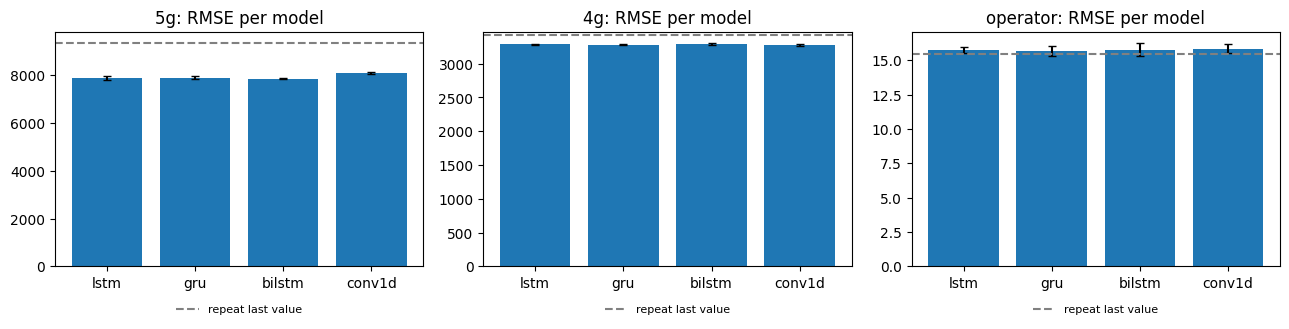

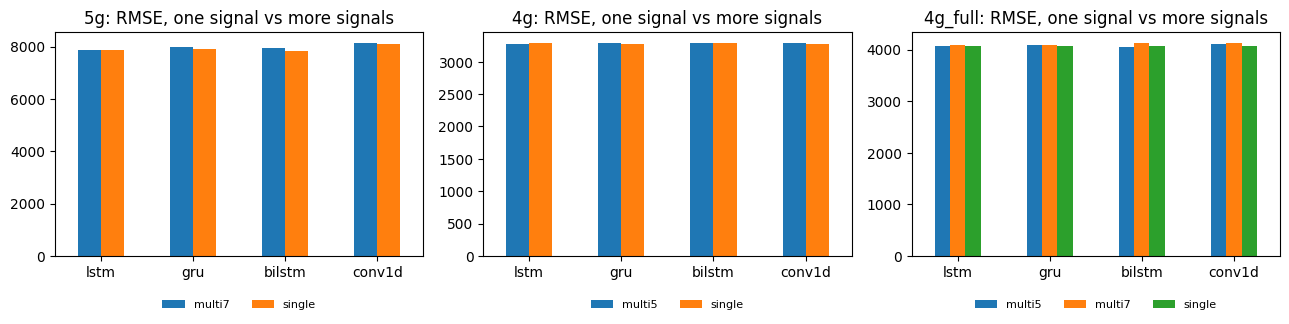

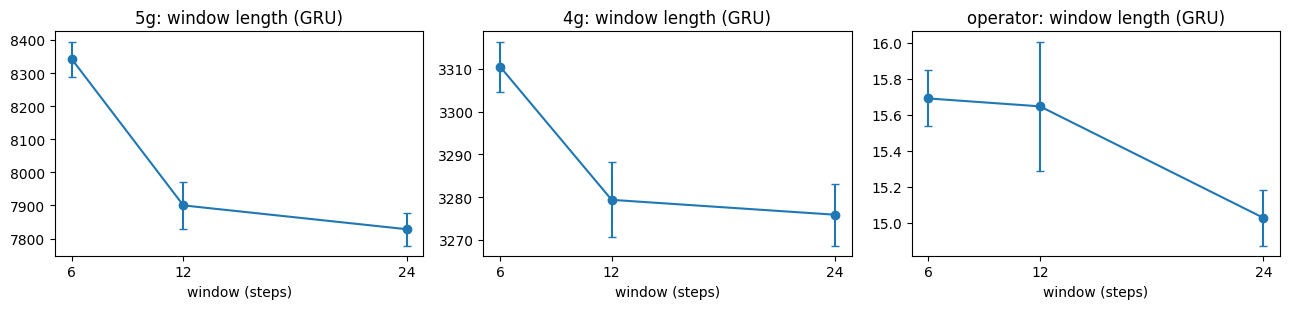

In [22]:
runs, tr = pd.read_csv(RUN_CSV), pd.read_csv(TRACE_CSV)
per_run = tr.groupby("run_id").agg(MAE=("MAE", "mean"), RMSE=("RMSE", "mean"),
                                   R2=("R2", "median"), dir_acc=("dir_acc", "mean")).reset_index()
full = runs.merge(per_run, on="run_id")
G = ["dataset", "colset", "window", "model"]
agg = full.groupby(G).agg(RMSE=("RMSE", "mean"), RMSE_sd=("RMSE", "std"), MAE=("MAE", "mean"),
                          R2=("R2", "mean"), dir_acc=("dir_acc", "mean"), train_s=("train_s", "mean"),
                          params=("params", "first"), seeds=("seed", "nunique")).reset_index()
agg.to_csv(RES + "/neural_summary.csv", index=False)

# ---- Experiment 1 table (+ the sanity reference)
pd.set_option("display.width", 200)
last_rmse = {}
for ds in DATASETS:
    colset, names = EXP1[ds]
    last_rmse[ds] = last_value_rmse(get_data(ds, names, WINDOW))
    t = agg[(agg.dataset == ds) & (agg.colset == colset) & (agg.window == WINDOW)].set_index("model").reindex(MODELS)
    print(f"\n=== {ds} (Experiment 1)   [sanity: 'repeat last value' RMSE = {last_rmse[ds]:.3f}]")
    print(t[["RMSE", "RMSE_sd", "MAE", "R2", "dir_acc", "train_s", "params", "seeds"]].round(3).to_string())

# ---- Plot 1: Experiment 1
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, ds in zip(axes, DATASETS):
    colset = EXP1[ds][0]
    t = agg[(agg.dataset == ds) & (agg.colset == colset) & (agg.window == WINDOW)].set_index("model").reindex(MODELS)
    ax.bar(MODELS, t.RMSE, yerr=t.RMSE_sd.fillna(0), capsize=3)
    ax.axhline(last_rmse[ds], ls="--", c="gray", label="repeat last value")
    ax.set_title(f"{ds}: RMSE per model")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout(); plt.subplots_adjust(bottom=0.2); plt.savefig(RES + "/plot_exp1.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Plot 2: Experiment 3 (extra signals)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, ds in zip(axes, ["5g", "4g", "4g_full"]):
    sub = agg[(agg.dataset == ds) & (agg.window == WINDOW)]
    if len(sub):
        sub.pivot(index="model", columns="colset", values="RMSE").reindex(MODELS).plot.bar(ax=ax, rot=0)
    ax.set_title(f"{ds}: RMSE, one signal vs more signals"); ax.set_xlabel("")
    if ax.get_legend(): ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(RES + "/plot_exp3_signals.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Plot 3: window length (GRU)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, ds in zip(axes, DATASETS):
    sub = agg[(agg.dataset == ds) & (agg.colset == EXP1[ds][0]) & (agg.model == "gru")].sort_values("window")
    ax.errorbar(sub.window, sub.RMSE, yerr=sub.RMSE_sd.fillna(0), marker="o", capsize=3)
    ax.set_xticks(sub.window); ax.set_title(f"{ds}: window length (GRU)"); ax.set_xlabel("window (steps)")
plt.tight_layout(); plt.savefig(RES + "/plot_window.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Pick the best models
Chooses the **2 best models per dataset using the validation loss** (not the test results, which would be unfair), and saves the list to `best_models.csv`.

**You should see:** a short table, then the list of files in the results folder.

In [23]:
e1 = full[[bool(r.dataset in EXP1 and r.colset == EXP1[r.dataset][0] and r.window == WINDOW)
           for r in full.itertuples()]]
best = (e1.groupby(["dataset", "model"]).best_val.mean().reset_index()
          .sort_values(["dataset", "best_val"]))
top2 = best.groupby("dataset").head(2)
print("Best 2 models per dataset (lowest validation loss, not test):")
print(top2.to_string(index=False))

rows = []
for r in top2.itertuples():
    for s in SEEDS:
        rows.append(dict(dataset=r.dataset, model=r.model, seed=s, val_loss=r.best_val,
                         checkpoint=f"{RES}/models/{r.dataset}__{EXP1[r.dataset][0]}__{r.model}__s{s}.pt"))
pd.DataFrame(rows).to_csv(RES + "/best_models.csv", index=False)
print("\nSaved the list to", RES + "/best_models.csv")
print("Files for Member B:", sorted(os.listdir(RES)))

Best 2 models per dataset (lowest validation loss, not test):
 dataset  model  best_val
      4g    gru  0.094021
      4g conv1d  0.094193
      5g   lstm  0.124258
      5g bilstm  0.125631
operator    gru  0.002690
operator conv1d  0.002702

Saved the list to /content/drive/MyDrive/dtn_project/results/best_models.csv
Files for Member B: ['best_models.csv', 'error_analysis', 'hyperparams_search.csv', 'models', 'neural_runs.csv', 'neural_summary.csv', 'neural_trace_results.csv', 'plot_exp1.png', 'plot_exp3_signals.png', 'plot_window.png']


In [24]:
for ds in ["5g", "4g", "4g_full"]:
    sub = agg[(agg.dataset == ds) & (agg.window == WINDOW)]
    print(f"\n=== {ds}: RMSE, one signal vs more signals")
    print(sub.pivot(index="model", columns="colset", values="RMSE").reindex(MODELS).round(1).to_string())
print("\n=== Window length (GRU), RMSE")
for ds in DATASETS:
    sub = agg[(agg.dataset == ds) & (agg.colset == EXP1[ds][0]) & (agg.model == "gru")]
    print(ds, sub.sort_values("window").set_index("window")[["RMSE", "RMSE_sd"]].round(2).T.to_string())
print("\n=== Repeat-last-value reference")
for ds in DATASETS:
    D = get_data(ds, EXP1[ds][1], WINDOW); rows = []
    for X, y in D["test"].values():
        last = X[:, -1, 0] * D["sd0"] + D["mu0"]; yt = y * D["sd0"] + D["mu0"]
        rows.append(metrics(yt, last, last))
    print(ds, "MAE", round(np.mean([r["MAE"] for r in rows]), 1),
          "RMSE", round(np.mean([r["RMSE"] for r in rows]), 1),
          "R2 (median)", round(float(np.nanmedian([r["R2"] for r in rows])), 3))


=== 5g: RMSE, one signal vs more signals
colset  multi7  single
model                 
lstm    7880.1  7868.6
gru     7970.3  7900.2
bilstm  7956.3  7843.5
conv1d  8149.3  8096.2

=== 4g: RMSE, one signal vs more signals
colset  multi5  single
model                 
lstm    3271.6  3286.5
gru     3288.8  3279.3
bilstm  3291.4  3294.5
conv1d  3292.7  3277.3

=== 4g_full: RMSE, one signal vs more signals
colset  multi5  multi7  single
model                         
lstm    4078.1  4092.7  4067.7
gru     4082.9  4096.1  4077.3
bilstm  4054.6  4135.4  4073.9
conv1d  4118.9  4129.1  4070.1

=== Window length (GRU), RMSE
5g window        6       12       24
RMSE     8342.18  7900.2  7828.29
RMSE_sd    52.86    70.1    49.26
4g window        6        12       24
RMSE     3310.55  3279.34  3275.86
RMSE_sd     5.87     8.77     7.22
operator window      6      12     24
RMSE     15.69  15.65  15.03
RMSE_sd   0.16   0.36   0.15

=== Repeat-last-value reference
5g MAE 4572.2 RMSE 9352.8 R2 (medi

In [25]:
r = pd.read_csv(RUN_CSV)
print("finished runs:", len(r), "(expected 114)")
print(r.groupby("dataset").size().to_string())
print("saved models:", len(os.listdir(RES + "/models")), "(expected 36)")
print("best_models.csv exists:", os.path.exists(RES + "/best_models.csv"))

finished runs: 114 (expected 114)
dataset
4g          30
4g_full     36
5g          30
operator    18
saved models: 36 (expected 36)
best_models.csv exists: True
